## Graph 1: Frequency of AI Usage Across Study Activities

**Graph Type:** Heatmap

**Description:** This heatmap compares how frequently students use AI for different study activities. The rows represent study activities, while the columns represent AI usage frequency levels. Darker blue colors indicate higher percentages of students selecting a response.

**Hypothesis:** Students are more likely to use AI frequently for understanding and reviewing information, such as asking questions, finding definitions, reviewing lecture slides, and correcting written mistakes, than for completing STEM homework, writing assignments, or checking calculation mistakes.

**Takeaway:** Students report using AI very often for correcting written mistakes (63.0%), asking definitions (60.3%), asking questions (57.1%), and reviewing lecture slides (56.8%). In contrast, fewer students report using AI very often for STEM homework (23.9%), checking calculation mistakes (23.8%), and writing assignments (21.6%). This suggests that AI is more frequently used for learning and reviewing information than for assignment-related or calculation-based tasks.

**Status:** Graph completed.

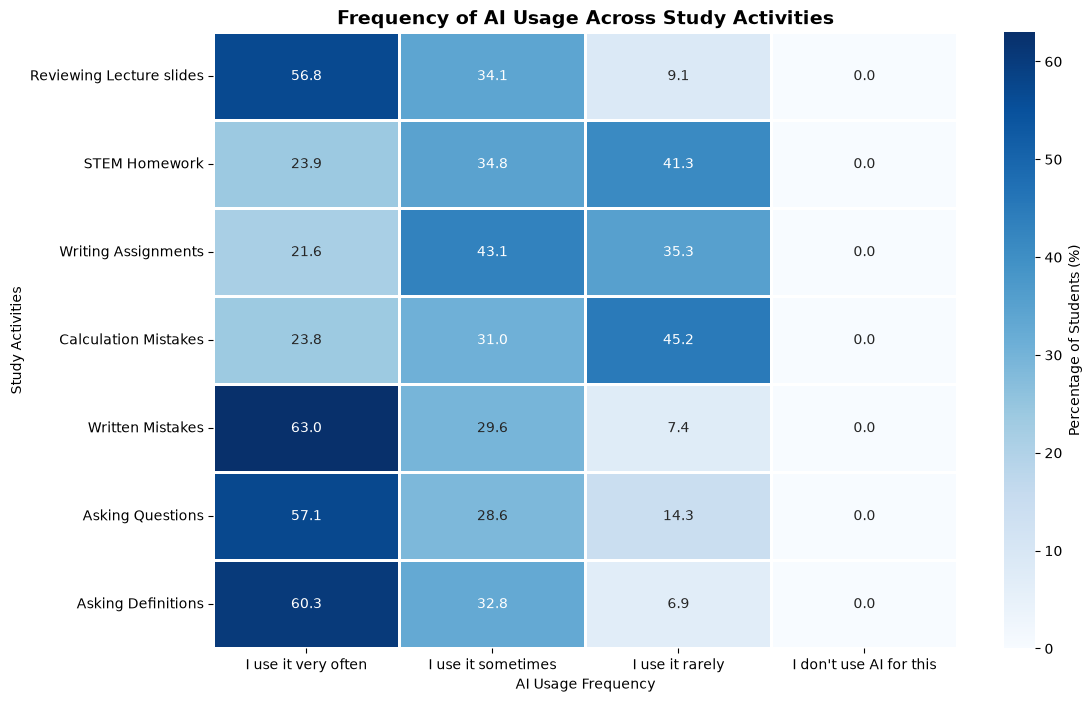

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

survey_df = pd.read_csv("survey.csv")
# create crosstable that limit x-axis as "i don't use AI for this, i use it rarelly, etc"
# y-axis as types of questions: "reviewing lecture slides, doing homework for STEM related subjects, etc"
study_df = survey_df.loc[:, "How often do you use AI for the following:\n [Reviewing Lecture slides]": "How often do you use AI for the following:\n [Asking for definitions]"]
study_df["How often do you use AI for the following:\n [Reviewing Lecture slides]"].value_counts()

# Count responses for each study activity
lecture = study_df.iloc[:, 0].value_counts()
stem = study_df.iloc[:, 1].value_counts()
writing = study_df.iloc[:, 2].value_counts()
calculation = study_df.iloc[:, 3].value_counts()
written_review = study_df.iloc[:, 4].value_counts()
questions = study_df.iloc[:, 5].value_counts()
definitions = study_df.iloc[:, 6].value_counts()

# Combine the counts into one DataFrame
cross_survey = pd.DataFrame({
    "Reviewing Lecture slides": lecture,
    "STEM Homework": stem,
    "Writing Assignments": writing,
    "Calculation Mistakes": calculation,
    "Written Mistakes": written_review,
    "Asking Questions": questions,
    "Asking Definitions": definitions
}).T
# Data have blank value. Replace missing values with 0
cross_survey = cross_survey.fillna(0)

# Set the order of frequency responses (x-axis) and reorder it
response_order = ["I use it very often", "I use it sometimes","I use it rarely", "I don't use AI for this"]
cross_survey = cross_survey.reindex(columns=response_order, fill_value=0)

# Calculate percentages for each study activity
percentage_survey = cross_survey.div(cross_survey.sum(axis=1), axis=0) * 100

# Create a heatmap
# Set figure size for better readability
plt.figure(figsize=(12, 8))

# cmap='Blues': Darker blue represents a higher percentage
# annot=True: Displays the percentages in each cell
# fmt='.1f': Shows percentages with 1 decimal place
# linewidths=1: Adds spacing between cells
sns.heatmap(percentage_survey, cmap='Blues', annot=True, fmt='.1f',
            linewidths=1, cbar_kws={'label': 'Percentage of Students (%)'})

# Add title and labels
plt.title('Frequency of AI Usage Across Study Activities', fontsize=14, fontweight='bold')
plt.xlabel('AI Usage Frequency')
plt.ylabel('Study Activities')
plt.show()



## Graph 2: Homework Strategies Under Different Deadline Pressures

**Graph Type:** Stacked Bar Chart

**Description:** This stacked bar chart will show the percentage of students who prefer different homework-solving strategies depending on the time remaining before a deadline. Each bar represents a different amount of time remaining, while the segments represent strategies such as solving problems independently, asking AI for hints or explanations, or asking AI for complete solutions. The graph will compare how students' preferred strategies differ across deadline conditions.

**Hypothesis:** As deadline pressure increases, students are more likely to rely on AI for homework assistance, including asking for hints, explanations, or complete solutions, rather than solving problems independently.

**Takeaway:** This graph will help identify how students' preferred homework-solving strategies differ depending on deadline pressure. The main goal is to compare the percentages of students choosing each strategy across different deadline conditions and determine whether AI assistance becomes more common when students have less time to complete their homework.

**Status:** Planned / Not started.

<Figure size 1200x700 with 0 Axes>

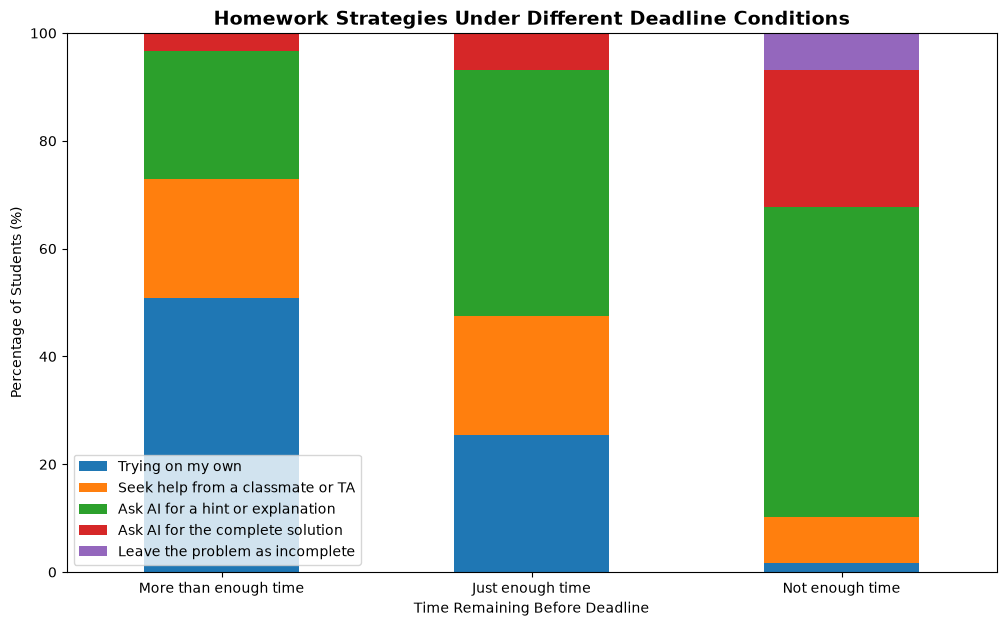

In [ ]:

import matplotlib.pyplot as plt

# Clean up the data by selecting the three homework strategy questions
homework_df = survey_df.loc[:, "If you have been working on a homework problem for 15 minutes without making any progress, what action are you most likely to take in each of the following scenarios? [When you have more than enough time to finish your assignment before the deadline]" : "If you have been working on a homework problem for 15 minutes without making any progress, what action are you most likely to take in each of the following scenarios? [When you don’t have enough time to finish your assignment before the deadline]"]

# Count the responses for each deadline situation
more_time = homework_df.iloc[:, 0].value_counts()
just_enough = homework_df.iloc[:, 1].value_counts()
not_enough = homework_df.iloc[:, 2].value_counts()

# Combine the counts into one DataFrame
cross_homework = pd.DataFrame({
    "More than enough time": more_time,
    "Just enough time": just_enough,
    "Not enough time": not_enough
}).T

# Replace missing response with 0
cross_homework = cross_homework.fillna(0)

# Set the order of homework strategies
strategy_order = [
    "Trying on my own",
    "Seek help from a classmate or TA",
    "Ask AI for a hint or explanation",
    "Ask AI for the complete solution",
    "Leave the problem as incomplete"
]

# Reorder the columns
cross_homework = cross_homework.reindex(columns=strategy_order, fill_value=0)


# Calculate the percentage of each homework strategy for each deadline situation
# Divide each count by the total responses in its row
percentage_homework = cross_homework.div(cross_homework.sum(axis=1), axis=0) * 100


# Create a 100% stacked bar chart to compare homework strategies under different deadline conditions
# Set figure size for better readability
plt.figure(figsize=(12, 7))

# Create the stacked bar chart
# stacked=True: Stacks different homework strategies into one bar
# Each bar represents 100% of responses for one deadline situation
percentage_homework.plot.bar(stacked=True, figsize=(12, 7))

# Add title and axis labels
plt.title('Homework Strategies Under Different Deadline Conditions', fontsize=14, fontweight='bold')
plt.xlabel('Time Remaining Before Deadline')
plt.ylabel('Percentage of Students (%)')

# Set the y-axis range from 0% to 100%
plt.ylim(0, 100)

# Rotate x-axis labels for readability
plt.xticks(rotation=0)

# Display the chart
plt.show()